# TP 2 - Deep Learning pour le NLP

Sami Nakib, cours de NLP (CY Tech, 6A).

On reprend exactement la tâche et le jeu de test du TP 1 (prédire lequel des 5 locuteurs principaux prononce une réplique d'au moins 5 mots) pour comparer des approches deep learning aux modèles linéaires sur TF-IDF :

- Modèles classiques : Naive Bayes, régression logistique, SVM linéaire.
- Réseaux de neurones : MLP sur TF-IDF, sac d'embeddings, BiLSTM et BiGRU sur séquences de tokens.

Pour comparer proprement, les hyperparamètres et l'arrêt précoce sont réglés sur un jeu de validation séparé du test, et chaque réseau est entraîné sur 5 graines pour mesurer sa variance.

## 0. Imports et configuration

In [1]:
import re
import copy
import time
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
pd.set_option("display.width", 140)

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})
COULEURS = ["#2a78d6", "#eb6834", "#1baf7a"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__}, device : {device}")

PyTorch 2.6.0+cpu, device : cpu


## 1. Chargement du corpus et reprise de la tâche du TP 1

On charge Tiny Shakespeare et on applique le même filtrage que dans le TP 1 (5 locuteurs les plus fréquents, répliques de 5 mots minimum).

In [2]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
texte = urllib.request.urlopen(URL).read().decode("utf-8")


def parser_repliques(txt: str) -> pd.DataFrame:
    """Extrait les paires (locuteur, replique) depuis le texte brut."""
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)
df["n_mots"] = df["replique"].str.split().str.len()

N_LOCUTEURS = 5
MIN_MOTS = 5
top_locuteurs = df["locuteur"].value_counts().head(N_LOCUTEURS).index

donnees = (
    df[df["locuteur"].isin(top_locuteurs) & (df["n_mots"] >= MIN_MOTS)]
    .loc[:, ["replique", "locuteur"]]
    .reset_index(drop=True)
)

print(f"Corpus : {len(df):,} répliques, {df['locuteur'].nunique()} locuteurs")
print(f"Sélection : {len(donnees)} répliques, {N_LOCUTEURS} locuteurs\n")
print(donnees["locuteur"].value_counts().to_string())
print(f"\nDoublons dans les répliques : {donnees.duplicated('replique').sum()}")

Corpus : 7,094 répliques, 297 locuteurs
Sélection : 761 répliques, 5 locuteurs

locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126

Doublons dans les répliques : 0


Aucune réplique n'est en double, donc aucun texte identique ne risque de passer à la fois en train et en test.

## 2. Découpage train / validation / test

Comme les réseaux de neurones demandent un jeu de validation (pour l'arrêt précoce et le choix des hyperparamètres), on reproduit d'abord le premier `train_test_split` du TP 1 pour garder exactement les mêmes 153 répliques de test, puis on prélève 15 % du reste pour la validation.

In [3]:
X_trval, X_test, y_trval, y_test = train_test_split(
    donnees["replique"], donnees["locuteur"],
    test_size=0.20, stratify=donnees["locuteur"], random_state=RANDOM_STATE,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trval, y_trval,
    test_size=0.15, stratify=y_trval, random_state=RANDOM_STATE,
)

print(f"train : {len(X_train)} | validation : {len(X_val)} | test : {len(X_test)}\n")
print(pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3).to_string())

encodeur = LabelEncoder().fit(y_train)
CLASSES = encodeur.classes_
K = len(CLASSES)
ytr, yva, yte = (encodeur.transform(y) for y in (y_train, y_val, y_test))

train : 516 | validation : 92 | test : 153

                train  validation   test
locuteur                                
GLOUCESTER      0.256       0.261  0.261
DUKE VINCENTIO  0.217       0.217  0.216
ROMEO           0.186       0.185  0.183
PETRUCHIO       0.174       0.174  0.176
MENENIUS        0.167       0.163  0.163


Le train passe de 608 à 516 répliques à cause du prélèvement de validation, ce qui fera légèrement baisser les scores ML par rapport au TP 1, mais permet une comparaison sans fuite vers le test.

## 3. Prétraitement et encodage en séquences

Les modèles ML et le MLP prennent directement les vecteurs TF-IDF. Pour le sac d'embeddings, le BiLSTM et le BiGRU, il faut transformer chaque réplique en séquence d'identifiants entiers :

- Découpage au niveau du mot en minuscules, en gardant les apostrophes internes (`know't`, `o'er`) ainsi que `!` et `?` qui marquent l'intonation.
- Pas de lemmatisation ni de suppression des mots vides : des formes comme `thou`, `thy` ou `sir` restent utiles pour distinguer les registres.
- Construction du vocabulaire sur le train seul, avec `min_freq = 2` (les mots vus une seule fois passent en `<unk>`).

In [4]:
MOTIF_TOKEN = re.compile(r"[a-z]+(?:'[a-z]+)*|[!?]")


def tokeniser(texte: str) -> list:
    return MOTIF_TOKEN.findall(texte.lower())


PAD, UNK = 0, 1
MIN_FREQ = 2


def construire_vocab(textes, tok=tokeniser, min_freq=MIN_FREQ):
    """Construit les tables mot <-> id avec 0=<pad> et 1=<unk>."""
    compteur = Counter(m for t in textes for m in tok(t))
    itos = ["<pad>", "<unk>"] + [m for m, c in compteur.most_common() if c >= min_freq]
    return {m: i for i, m in enumerate(itos)}, itos


stoi, itos = construire_vocab(X_train)


def taux_inconnus(textes):
    toks = [m for t in textes for m in tokeniser(t)]
    return sum(m not in stoi for m in toks) / len(toks)


print(f"Vocabulaire : {len(itos):,} tokens (avec <pad> et <unk>)")
print("Tokens fréquents :", itos[2:18])
for nom, X in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    print(f"Taux de <unk> ({nom}) : {taux_inconnus(X):.1%}")

Vocabulaire : 1,387 tokens (avec <pad> et <unk>)
Tokens fréquents : ['the', 'and', 'to', 'i', 'you', 'of', 'a', 'that', 'my', 'in', '?', 'is', 'not', 'for', 'me', '!']
Taux de <unk> (train) : 11.1%
Taux de <unk> (validation) : 18.4%
Taux de <unk> (test) : 16.1%


Sur un aussi petit jeu d'entraînement (516 répliques), le vocabulaire reste réduit (~1 400 mots) et environ 16 à 18 % des tokens de validation et de test tombent dans `<unk>`. C'est une limite structurelle quand on apprend des embeddings de mots à partir de zéro sur peu de données.

Pour former des tenseurs rectangulaires par mini-batch, je fixe `MAX_LEN` au 95e centile des longueurs du train afin d'éviter de padder toutes les séquences à plus de 500 tokens pour quelques rares tirades.

Médiane : 18 tokens | Moyenne : 36.4 | Max : 589
MAX_LEN (95e centile) = 116 -> 5.0% des répliques tronquées


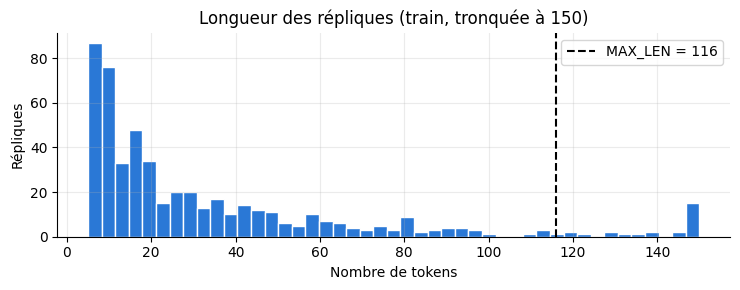

In [5]:
longueurs = np.array([len(tokeniser(t)) for t in X_train])
MAX_LEN = int(np.percentile(longueurs, 95))

print(f"Médiane : {np.median(longueurs):.0f} tokens | Moyenne : {longueurs.mean():.1f} | Max : {longueurs.max()}")
print(f"MAX_LEN (95e centile) = {MAX_LEN} -> {np.mean(longueurs > MAX_LEN):.1%} des répliques tronquées")

fig, ax = plt.subplots(figsize=(7.5, 3))
ax.hist(np.clip(longueurs, 0, 150), bins=45, color=COULEURS[0], edgecolor="white")
ax.axvline(MAX_LEN, color="black", ls="--", label=f"MAX_LEN = {MAX_LEN}")
ax.set_title("Longueur des répliques (train, tronquée à 150)")
ax.set_xlabel("Nombre de tokens")
ax.set_ylabel("Répliques")
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
def encoder_sequences(textes, stoi, max_len=MAX_LEN, tok=tokeniser):
    """Encode les textes en tenseurs d'ids paddés et renvoie leurs longueurs réelles."""
    ids = torch.full((len(textes), max_len), PAD, dtype=torch.long)
    lens = torch.zeros(len(textes), dtype=torch.long)
    for i, t in enumerate(textes):
        seq = [stoi.get(m, UNK) for m in tok(t)][:max_len] or [UNK]
        ids[i, :len(seq)] = torch.tensor(seq)
        lens[i] = len(seq)
    return ids, lens


ids_tr, len_tr = encoder_sequences(X_train, stoi)
ex = X_train.iloc[0]
print("Exemple :", ex[:80])
print("Ids     :", ids_tr[0, :12].tolist())
print("Décodé  :", [itos[i] for i in ids_tr[0, :12].tolist()])
print(f"Shape ids_tr : {tuple(ids_tr.shape)}, len_tr : {tuple(len_tr.shape)}")

Exemple : Well, sir, in brief, the gown is not for me.
Ids     : [48, 103, 11, 497, 2, 864, 13, 14, 15, 16, 0, 0]
Décodé  : ['well', 'sir', 'in', 'brief', 'the', 'gown', 'is', 'not', 'for', 'me', '<pad>', '<pad>']
Shape ids_tr : (516, 116), len_tr : (516,)


## 4. Représentations : TF-IDF et embeddings

On prépare le vectoriseur TF-IDF avec les mêmes réglages qu'au TP 1, puis on vérifie les dimensions produites par une couche `nn.Embedding` suivie d'un `nn.LSTM` bidirectionnel sur 4 exemples.

In [7]:
def nouveau_tfidf(**options):
    return TfidfVectorizer(
        lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.8,
        sublinear_tf=True, **options,
    )


vectoriseur = nouveau_tfidf()
Xtr_tfidf = vectoriseur.fit_transform(X_train)
Xva_tfidf = vectoriseur.transform(X_val)
Xte_tfidf = vectoriseur.transform(X_test)
print(f"TF-IDF train : {Xtr_tfidf.shape}, densité : {Xtr_tfidf.nnz / np.prod(Xtr_tfidf.shape):.2%}")

torch.manual_seed(0)
emb = nn.Embedding(len(itos), 100, padding_idx=PAD)
lstm = nn.LSTM(100, 64, batch_first=True, bidirectional=True)
xb = ids_tr[:4]
e = emb(xb)
sorties, (h_n, _) = lstm(e)

print(f"xb : {tuple(xb.shape)} -> emb : {tuple(e.shape)} -> sorties : {tuple(sorties.shape)}, h_n : {tuple(h_n.shape)}")

TF-IDF train : (516, 2958), densité : 1.11%


xb : (4, 116) -> emb : (4, 116, 100) -> sorties : (4, 116, 128), h_n : (2, 4, 64)


## 5. Modèles ML de référence

On réentraîne les 3 modèles du TP 1, mais en sélectionnant leur paramètre de régularisation (`alpha` ou `C`) sur le jeu de validation plutôt que par défaut.

In [8]:
grilles = {
    "Naive Bayes": (lambda v: MultinomialNB(alpha=v), "alpha", [0.05, 0.1, 0.3, 0.5, 1.0]),
    "Régression logistique": (
        lambda v: LogisticRegression(C=v, max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE),
        "C", [0.5, 1, 2, 5, 10, 20],
    ),
    "SVM linéaire": (
        lambda v: LinearSVC(C=v, class_weight="balanced", random_state=RANDOM_STATE),
        "C", [0.03, 0.1, 0.3, 1, 3],
    ),
}

modeles_ml, durees_ml, lignes = {}, {}, []
for nom, (fabrique, param, valeurs) in grilles.items():
    scores = {
        v: f1_score(yva, fabrique(v).fit(Xtr_tfidf, ytr).predict(Xva_tfidf), average="macro")
        for v in valeurs
    }
    v_retenu = max(scores, key=scores.get)
    t0 = time.perf_counter()
    modeles_ml[nom] = fabrique(v_retenu).fit(Xtr_tfidf, ytr)
    durees_ml[nom] = time.perf_counter() - t0
    lignes.append({
        "modèle": nom,
        "réglage retenu": f"{param} = {v_retenu}",
        "F1 macro (val)": scores[v_retenu],
        "grille (val)": "  ".join(f"{v}:{s:.2f}" for v, s in scores.items()),
    })

modeles_ml["Baseline (majoritaire)"] = DummyClassifier(strategy="most_frequent").fit(Xtr_tfidf, ytr)

selection_ml = pd.DataFrame(lignes).set_index("modèle")
meilleur_ml = selection_ml["F1 macro (val)"].idxmax()
print(f"Meilleur modèle ML sur la validation : {meilleur_ml}")
selection_ml.round(3)

Meilleur modèle ML sur la validation : Naive Bayes


,réglage retenu,F1 macro (val),grille (val)
modèle,,,
Naive Bayes,alpha = 0.05,0.623,0.05:0.62 0.1:0.59 0.3:0.60 0.5:0.57 1.0:0.49
Régression logistique,C = 5,0.618,0.5:0.60 1:0.59 2:0.61 5:0.62 10:0.60 20:...
SVM linéaire,C = 1,0.613,0.03:0.55 0.1:0.59 0.3:0.60 1:0.61 3:0.59


## 6. Modèles de deep learning

### 6.1 Architectures testées

1. `MLP` : une couche cachée de 256 neurones (ReLU + dropout 0,5) directement sur le vecteur TF-IDF.
2. `SacEmbeddings` : moyenne des embeddings de tokens (d = 64, sans compter le `<pad>`) suivie d'une projection linéaire.
3. `BiLSTM` et `BiGRU` : embeddings (d = 100) lus dans les deux sens (`d_cache = 64`), avec `pack_padded_sequence` pour ignorer le padding et concaténation des deux états finaux.

In [9]:
class MLP(nn.Module):
    def __init__(self, n_entree, n_cache=256, n_classes=K, dropout=0.5):
        super().__init__()
        self.reseau = nn.Sequential(
            nn.Linear(n_entree, n_cache),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_cache, n_classes),
        )

    def forward(self, x):
        return self.reseau(x)


class SacEmbeddings(nn.Module):
    def __init__(self, taille_vocab, d_emb=64, n_classes=K, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(taille_vocab, d_emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        self.sortie = nn.Linear(d_emb, n_classes)

    def forward(self, ids, longueurs):
        e = self.emb(ids)
        masque = (ids != PAD).unsqueeze(-1).float()
        moyenne = (e * masque).sum(1) / masque.sum(1).clamp(min=1)
        return self.sortie(self.drop(moyenne))


class RNNBidirectionnel(nn.Module):
    def __init__(self, taille_vocab, cellule="lstm", d_emb=100, d_cache=64, n_classes=K,
                 dropout_emb=0.3, dropout=0.5):
        super().__init__()
        self.emb = nn.Embedding(taille_vocab, d_emb, padding_idx=PAD)
        rnn = nn.LSTM if cellule == "lstm" else nn.GRU
        self.rnn = rnn(d_emb, d_cache, batch_first=True, bidirectional=True)
        self.drop_emb = nn.Dropout(dropout_emb)
        self.drop = nn.Dropout(dropout)
        self.sortie = nn.Linear(2 * d_cache, n_classes)

    def forward(self, ids, longueurs):
        e = self.drop_emb(self.emb(ids))
        paquet = pack_padded_sequence(e, longueurs.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(paquet)
        if isinstance(h, tuple):
            h = h[0]
        h = torch.cat([h[-2], h[-1]], dim=1)
        return self.sortie(self.drop(h))


ARCHITECTURES = {
    "MLP (TF-IDF)":     dict(entree="tfidf", lr=1e-3, epoques=60, patience=10),
    "Sac d'embeddings": dict(entree="seq", lr=5e-3, epoques=100, patience=15),
    "BiLSTM":           dict(entree="seq", cellule="lstm", lr=3e-3, epoques=60, patience=10),
    "BiGRU":            dict(entree="seq", cellule="gru", lr=3e-3, epoques=60, patience=10),
}


def fabriquer(nom, P):
    cfg = ARCHITECTURES[nom]
    if cfg["entree"] == "tfidf":
        return MLP(P["n_entree"])
    if nom == "Sac d'embeddings":
        return SacEmbeddings(P["taille_vocab"])
    return RNNBidirectionnel(P["taille_vocab"], cfg["cellule"])


def n_parametres(modele):
    return sum(p.numel() for p in modele.parameters() if p.requires_grad)

### 6.2 Préparation des tenseurs et boucle d'entraînement

La fonction `preparer` regroupe tout ce qui dépend du jeu d'entraînement (TF-IDF, vocabulaire, poids de classe) pour pouvoir la réutiliser proprement dans les ablations de la section 8. L'entraînement utilise AdamW, une perte pondérée par classe, un gradient clipping à 1,0 et un arrêt précoce sur le F1 macro de validation.

In [10]:
def jeu_tfidf(X, y):
    return TensorDataset(torch.tensor(X.toarray(), dtype=torch.float32), torch.tensor(y))


def jeu_seq(ids, lens, y):
    return TensorDataset(ids, lens, torch.tensor(y))


def preparer(X_tr, y_tr, tok=tokeniser, mots_exclus=None):
    vec = nouveau_tfidf(stop_words=mots_exclus).fit(X_tr)
    stoi_, itos_ = construire_vocab(X_tr, tok)
    sources = {"train": (X_tr, y_tr), "val": (X_val, yva), "test": (X_test, yte)}
    return {
        "vec": vec, "stoi": stoi_, "itos": itos_,
        "tfidf": {s: jeu_tfidf(vec.transform(X), y) for s, (X, y) in sources.items()},
        "seq": {s: jeu_seq(*encoder_sequences(X, stoi_, tok=tok), y) for s, (X, y) in sources.items()},
        "taille_vocab": len(itos_), "n_entree": len(vec.vocabulary_),
        "poids": torch.tensor(
            compute_class_weight("balanced", classes=np.arange(K), y=y_tr),
            dtype=torch.float32,
        ),
    }


def predire(modele, jeu, fn_perte=None):
    modele.eval()
    preds, perte, n = [], 0.0, 0
    with torch.no_grad():
        for *entrees, y in DataLoader(jeu, batch_size=512):
            entrees, y = [t.to(device) for t in entrees], y.to(device)
            logits = modele(*entrees)
            if fn_perte is not None:
                perte += fn_perte(logits, y).item() * len(y)
            n += len(y)
            preds.append(logits.argmax(1).cpu())
    return torch.cat(preds).numpy(), perte / n


def entrainer(modele, jeu_train, jeu_val, lr, epoques, patience, graine, poids,
              taille_batch=32, weight_decay=1e-2, clip=1.0):
    modele = modele.to(device)
    melange = torch.Generator().manual_seed(graine)
    chargeur = DataLoader(jeu_train, batch_size=taille_batch, shuffle=True, generator=melange)
    optimiseur = torch.optim.AdamW(modele.parameters(), lr=lr, weight_decay=weight_decay)
    fn_perte = nn.CrossEntropyLoss(weight=poids.to(device))
    y_val_np = jeu_val.tensors[-1].numpy()

    historique, meilleur, attente = [], {"f1": -1.0}, 0
    for epoque in range(1, epoques + 1):
        modele.train()
        somme, n = 0.0, 0
        for *entrees, y in chargeur:
            entrees, y = [t.to(device) for t in entrees], y.to(device)
            optimiseur.zero_grad(set_to_none=True)
            perte = fn_perte(modele(*entrees), y)
            perte.backward()
            nn.utils.clip_grad_norm_(modele.parameters(), clip)
            optimiseur.step()
            somme += perte.item() * len(y)
            n += len(y)

        pred_val, perte_val = predire(modele, jeu_val, fn_perte)
        f1_val = f1_score(y_val_np, pred_val, average="macro")
        historique.append({
            "époque": epoque,
            "perte train": somme / n,
            "perte validation": perte_val,
            "F1 validation": f1_val,
        })

        if f1_val > meilleur["f1"]:
            meilleur = {"f1": f1_val, "époque": epoque, "poids": copy.deepcopy(modele.state_dict())}
            attente = 0
        else:
            attente += 1
            if attente >= patience:
                break

    modele.load_state_dict(meilleur["poids"])
    return modele, pd.DataFrame(historique), meilleur["époque"]


def entrainer_dl(nom, P, graine):
    cfg = ARCHITECTURES[nom]
    torch.manual_seed(graine)
    jeux = P[cfg["entree"]]
    return entrainer(
        fabriquer(nom, P), jeux["train"], jeux["val"],
        lr=cfg["lr"], epoques=cfg["epoques"], patience=cfg["patience"],
        graine=graine, poids=P["poids"],
    )


P = preparer(X_train, ytr)
print(f"Vocabulaire : {P['taille_vocab']:,} | TF-IDF : {P['n_entree']:,} colonnes")
print(f"{'modèle':<18}{'paramètres':>12}{'params / exemple train':>26}")
for nom in ARCHITECTURES:
    n = n_parametres(fabriquer(nom, P))
    print(f"{nom:<18}{n:>12,}{n / len(X_train):>26,.0f}")

Vocabulaire : 1,387 | TF-IDF : 2,958 colonnes
modèle              paramètres    params / exemple train
MLP (TF-IDF)           758,789                     1,471
Sac d'embeddings        89,093                       173
BiLSTM                 224,337                       435
BiGRU                  203,089                       394


Ces réseaux ont entre 89 000 et 759 000 paramètres pour 516 répliques d'entraînement, contre ~15 000 pour Naive Bayes ou la régression logistique. Ils peuvent donc facilement apprendre le train par coeur sans régularisation ni arrêt précoce.

### 6.3 Entraînement des 4 architectures sur 5 graines

In [11]:
GRAINES = [0, 1, 2, 3, 4]
modeles_dl, historiques, resume = {}, {}, []

for nom in ARCHITECTURES:
    for graine in GRAINES:
        t0 = time.perf_counter()
        modele, hist, ep = entrainer_dl(nom, P, graine)
        modeles_dl[(nom, graine)] = modele
        if graine == 0:
            historiques[nom] = hist
        resume.append({
            "modèle": nom, "graine": graine, "meilleure époque": ep,
            "époques jouées": len(hist), "F1 validation": hist["F1 validation"].max(),
            "durée (s)": time.perf_counter() - t0,
        })
    r = pd.DataFrame([x for x in resume if x["modèle"] == nom])
    print(f"{nom:<18} F1 val = {r['F1 validation'].mean():.3f} +/- {r['F1 validation'].std():.3f}  "
          f"(ep. médiane {r['meilleure époque'].median():.0f}, {r['durée (s)'].mean():.1f} s/run)")

resume = pd.DataFrame(resume)
meilleur_dl = resume.groupby("modèle")["F1 validation"].mean().idxmax()
print(f"\nMeilleur réseau sur la validation : {meilleur_dl}")

MLP (TF-IDF)       F1 val = 0.664 +/- 0.012  (ep. médiane 8, 1.6 s/run)


Sac d'embeddings   F1 val = 0.595 +/- 0.007  (ep. médiane 36, 6.3 s/run)


BiLSTM             F1 val = 0.421 +/- 0.046  (ep. médiane 15, 44.0 s/run)


BiGRU              F1 val = 0.433 +/- 0.039  (ep. médiane 16, 40.8 s/run)

Meilleur réseau sur la validation : MLP (TF-IDF)


### 6.4 Courbes d'apprentissage (graine 0)

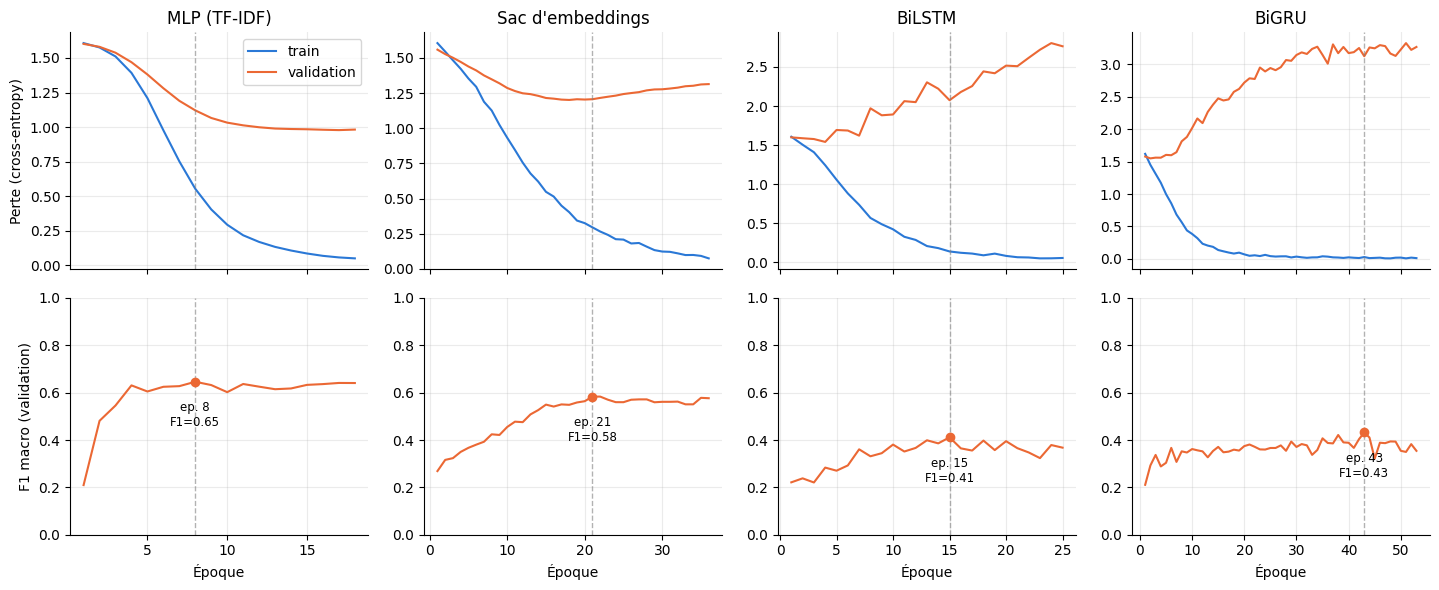

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(14.5, 6), sharex="col")
for j, (nom, hist) in enumerate(historiques.items()):
    haut, bas = axes[0, j], axes[1, j]
    haut.plot(hist["époque"], hist["perte train"], color=COULEURS[0], label="train")
    haut.plot(hist["époque"], hist["perte validation"], color=COULEURS[1], label="validation")
    haut.set_title(nom)

    i_best = hist["F1 validation"].idxmax()
    ep_best = hist.loc[i_best, "époque"]
    bas.plot(hist["époque"], hist["F1 validation"], color=COULEURS[1])
    bas.scatter(ep_best, hist.loc[i_best, "F1 validation"], color=COULEURS[1], zorder=3)
    bas.annotate(
        f"ep. {ep_best}\nF1={hist.loc[i_best, 'F1 validation']:.2f}",
        xy=(ep_best, hist.loc[i_best, "F1 validation"]),
        xytext=(0, -32), textcoords="offset points", ha="center", fontsize=8.5,
    )
    bas.set_ylim(0, 1)
    bas.set_xlabel("Époque")
    for ax in (haut, bas):
        ax.axvline(ep_best, color="gray", ls="--", lw=1, alpha=0.6)

axes[0, 0].set_ylabel("Perte (cross-entropy)")
axes[1, 0].set_ylabel("F1 macro (validation)")
axes[0, 0].legend(loc="upper right")
plt.tight_layout()
plt.show()

On retrouve le sur-apprentissage classique sur petit corpus :

- Pour tous les réseaux, la perte train descend vers zéro en 15 à 30 époques.
- Sur les deux RNN (BiLSTM et BiGRU), la perte de validation remonte très vite pendant que le F1 plafonne autour de 0,40.
- Le MLP atteint son meilleur F1 dès les premières époques. Sur le sac d'embeddings, la perte de validation remonte aussi après une vingtaine d'époques alors que le F1 continue parfois de monter : le modèle devient trop confiant sur ses erreurs, d'où l'intérêt de déclencher l'arrêt précoce sur le F1 plutôt que sur la perte.

## 7. Évaluation sur le test

### 7.1 Comparaison globale

In [13]:
def metriques(y_vrai, y_pred):
    return {
        "accuracy": accuracy_score(y_vrai, y_pred),
        "précision (macro)": precision_score(y_vrai, y_pred, average="macro", zero_division=0),
        "rappel (macro)": recall_score(y_vrai, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_vrai, y_pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_vrai, y_pred, average="weighted", zero_division=0),
    }


def n_parametres_ml(m):
    attributs = ["coef_", "intercept_", "feature_log_prob_", "class_log_prior_"]
    return int(sum(getattr(m, a).size for a in attributs if hasattr(m, a)))


preds_test, lignes = {}, []
for nom, m in modeles_ml.items():
    preds_test[nom] = m.predict(Xte_tfidf)
    lignes.append({
        "modèle": nom, "famille": "ML", **metriques(yte, preds_test[nom]),
        "std F1 (5 graines)": np.nan, "paramètres": n_parametres_ml(m),
        "durée (s)": durees_ml.get(nom, 0.0),
    })

for nom, cfg in ARCHITECTURES.items():
    par_graine = []
    for g in GRAINES:
        preds_test[(nom, g)], _ = predire(modeles_dl[(nom, g)], P[cfg["entree"]]["test"])
        par_graine.append(metriques(yte, preds_test[(nom, g)]))
    par_graine = pd.DataFrame(par_graine)
    lignes.append({
        "modèle": nom, "famille": "DL", **par_graine.mean().to_dict(),
        "std F1 (5 graines)": par_graine["F1 (macro)"].std(),
        "paramètres": n_parametres(modeles_dl[(nom, 0)]),
        "durée (s)": resume.loc[resume["modèle"] == nom, "durée (s)"].mean(),
    })

tableau = pd.DataFrame(lignes).set_index("modèle").sort_values("F1 (macro)", ascending=False)
tableau.round(3)

,famille,accuracy,précision (macro),rappel (macro),F1 (macro),F1 (weighted),std F1 (5 graines),paramètres,durée (s)
modèle,,,,,,,,,
Naive Bayes,ML,0.667,0.683,0.660,0.662,0.664,NaN,14795,0.001
MLP (TF-IDF),DL,0.646,0.652,0.646,0.644,0.646,0.019,758789,1.603
SVM linéaire,ML,0.634,0.636,0.635,0.633,0.635,NaN,14795,0.004
Régression logistique,ML,0.634,0.636,0.629,0.632,0.634,NaN,14795,0.084
Sac d'embeddings,DL,0.599,0.596,0.597,0.593,0.600,0.023,89093,6.312
BiGRU,DL,0.420,0.417,0.420,0.414,0.417,0.025,203089,40.825
BiLSTM,DL,0.413,0.428,0.419,0.413,0.411,0.028,224337,43.990
Baseline (majoritaire),ML,0.261,0.052,0.200,0.083,0.108,NaN,0,0.000


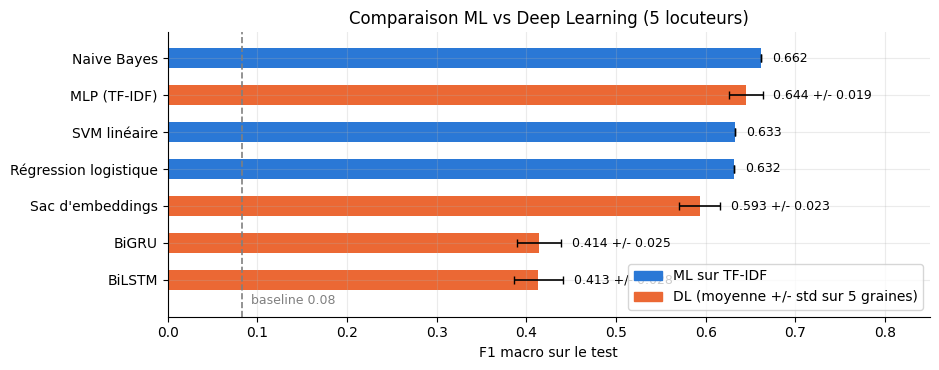

In [14]:
t = tableau.drop(index="Baseline (majoritaire)").sort_values("F1 (macro)")
y = np.arange(len(t))
sigma = t["std F1 (5 graines)"].fillna(0).to_numpy()

fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.barh(y, t["F1 (macro)"], height=0.55,
        color=[COULEURS[0] if f == "ML" else COULEURS[1] for f in t["famille"]])
ax.errorbar(t["F1 (macro)"], y, xerr=sigma, fmt="none", ecolor="black", elinewidth=1.2, capsize=3)
for yi, (v, s, fam) in enumerate(zip(t["F1 (macro)"], sigma, t["famille"])):
    txt = f"{v:.3f}" + (f" +/- {s:.3f}" if fam == "DL" else "")
    ax.text(v + s + 0.012, yi, txt, va="center", fontsize=9)

base = tableau.loc["Baseline (majoritaire)", "F1 (macro)"]
ax.axvline(base, color="gray", ls="--", lw=1.2)
ax.text(base + 0.01, -0.65, f"baseline {base:.2f}", color="gray", fontsize=9)

ax.set_yticks(y, t.index)
ax.set_xlim(0, 0.85)
ax.set_ylim(-1, len(t) - 0.3)
ax.set_xlabel("F1 macro sur le test")
ax.set_title("Comparaison ML vs Deep Learning (5 locuteurs)")
ax.legend(handles=[
    Patch(color=COULEURS[0], label="ML sur TF-IDF"),
    Patch(color=COULEURS[1], label="DL (moyenne +/- std sur 5 graines)"),
], loc="lower right")
plt.tight_layout()
plt.show()

Sur ces 516 répliques d'entraînement, le deep learning ne dépasse pas les modèles classiques :

- Naive Bayes arrive en tête avec 0,662 de F1 macro, juste devant le MLP sur TF-IDF (0,644 +/- 0,019) qui demande pourtant environ 50 fois plus de paramètres.
- Le sac d'embeddings tourne autour de 0,593, car il n'a ni bigrammes ni pondération IDF et part d'embeddings aléatoires.
- Le BiGRU (0,414) et le BiLSTM (0,413) restent loin derrière : ils ont plus de 200 000 paramètres à ajuster sur 516 phrases courtes, 16 % de mots inconnus au test, et l'état final doit résumer toute la réplique alors qu'un seul nom propre suffit souvent en TF-IDF.
- La régression logistique passe de 0,669 au TP 1 à 0,632 ici, simplement parce qu'on lui a retiré 92 exemples pour la validation.

                Naive Bayes  MLP (TF-IDF) (moy. 5 graines)  support test
DUKE VINCENTIO        0.675                          0.644            33
GLOUCESTER            0.691                          0.670            40
MENENIUS              0.679                          0.664            25
PETRUCHIO             0.681                          0.667            27
ROMEO                 0.583                          0.577            28 



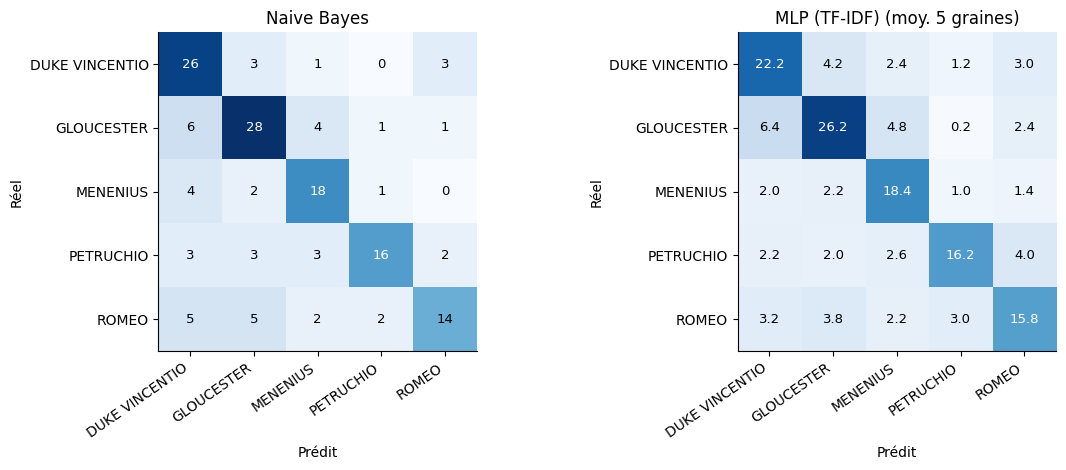

In [15]:
f1_par_classe = pd.DataFrame({
    meilleur_ml: f1_score(yte, preds_test[meilleur_ml], average=None),
    f"{meilleur_dl} (moy. 5 graines)": np.mean(
        [f1_score(yte, preds_test[(meilleur_dl, g)], average=None) for g in GRAINES], axis=0
    ),
    "support test": np.bincount(yte, minlength=K),
}, index=CLASSES)
print(f1_par_classe.round(3).to_string(), "\n")

cm_ml = confusion_matrix(yte, preds_test[meilleur_ml], labels=range(K))
cm_dl = np.mean([confusion_matrix(yte, preds_test[(meilleur_dl, g)], labels=range(K)) for g in GRAINES], axis=0)
vmax = max(cm_ml.max(), cm_dl.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, cm, titre, fmt in [
    (axes[0], cm_ml, meilleur_ml, "{:.0f}"),
    (axes[1], cm_dl, f"{meilleur_dl} (moy. 5 graines)", "{:.1f}"),
]:
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=vmax)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, fmt.format(cm[i, j]), ha="center", va="center", fontsize=9.5,
                    color="white" if cm[i, j] > 0.55 * vmax else "black")
    ax.set_xticks(range(K), CLASSES, rotation=35, ha="right")
    ax.set_yticks(range(K), CLASSES)
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
    ax.set_title(titre)
    ax.grid(False)
plt.tight_layout()
plt.show()

Les profils d'erreurs des deux meilleurs modèles se ressemblent beaucoup : Roméo est le moins bien reconnu par Naive Bayes, et les principales confusions restent entre Gloucester, Duke Vincentio et Ménénius qui partagent un lexique politique voisin (`lord`, `king`, `state`).

## 8. Analyses complémentaires

### 8.1 Sensibilité à l'initialisation (graines 0 à 4)

In [16]:
f1_graines = pd.DataFrame(
    {nom: [f1_score(yte, preds_test[(nom, g)], average="macro") for g in GRAINES] for nom in ARCHITECTURES},
    index=[f"graine {g}" for g in GRAINES],
)
resume_graines = pd.DataFrame({
    "moyenne": f1_graines.mean(),
    "écart-type": f1_graines.std(),
    "min": f1_graines.min(),
    "max": f1_graines.max(),
}).T
pd.concat([f1_graines, resume_graines]).round(3)

,MLP (TF-IDF),Sac d'embeddings,BiLSTM,BiGRU
graine 0,0.660,0.579,0.386,0.440
graine 1,0.630,0.589,0.456,0.430
graine 2,0.651,0.579,0.400,0.393
graine 3,0.662,0.634,0.400,0.383
graine 4,0.619,0.585,0.424,0.423
moyenne,0.644,0.593,0.413,0.414
écart-type,0.019,0.023,0.028,0.025
min,0.619,0.579,0.386,0.383
max,0.662,0.634,0.456,0.440


On voit qu'un seul entraînement peut tromper : selon la graine, le BiLSTM ou le sac d'embeddings bougent de 5 à 6 points de F1. D'où l'intérêt de moyenner sur plusieurs graines avant de conclure.

### 8.2 Est-ce que ML et DL font les mêmes erreurs ?

In [17]:
p_ml, p_dl = preds_test[meilleur_ml], preds_test[(meilleur_dl, 0)]
ok_ml, ok_dl = p_ml == yte, p_dl == yte

print(pd.crosstab(
    pd.Series(np.where(ok_ml, "juste", "faux"), name=meilleur_ml),
    pd.Series(np.where(ok_dl, "juste", "faux"), name=meilleur_dl),
), "\n")
print(f"Accord entre les deux : {np.mean(p_ml == p_dl):.0%}")
print(f"Au moins un correct   : {np.mean(ok_ml | ok_dl):.0%}\n")


def montrer(masque, titre, n=3):
    print(titre)
    for i in np.where(masque)[0][:n]:
        r = X_test.iloc[i]
        extrait = r[:160] + ("..." if len(r) > 160 else "")
        print(f"  vrai={CLASSES[yte[i]]} | {meilleur_ml}={CLASSES[p_ml[i]]} | {meilleur_dl}={CLASSES[p_dl[i]]}")
        print(f"  « {extrait} »\n")


montrer(ok_dl & ~ok_ml, f"{meilleur_dl} juste, {meilleur_ml} faux :")
montrer(ok_ml & ~ok_dl, f"{meilleur_ml} juste, {meilleur_dl} faux :")

MLP (TF-IDF)  faux  juste
Naive Bayes              
faux            47      4
juste            5     97 

Accord entre les deux : 88%
Au moins un correct   : 69%

MLP (TF-IDF) juste, Naive Bayes faux :
  vrai=ROMEO | Naive Bayes=GLOUCESTER | MLP (TF-IDF)=ROMEO
  « I'll tell thee, ere thou ask it me again. I have been feasting with mine enemy, Where on a sudden one hath wounded me, That's by me wounded: both our remedies W... »

  vrai=ROMEO | Naive Bayes=DUKE VINCENTIO | MLP (TF-IDF)=ROMEO
  « I must indeed; and therefore came I hither. Good gentle youth, tempt not a desperate man; Fly hence, and leave me: think upon these gone; Let them affright thee... »

  vrai=PETRUCHIO | Naive Bayes=DUKE VINCENTIO | MLP (TF-IDF)=PETRUCHIO
  « Not her that chides, sir, at any hand, I pray. »

Naive Bayes juste, MLP (TF-IDF) faux :
  vrai=GLOUCESTER | Naive Bayes=GLOUCESTER | MLP (TF-IDF)=DUKE VINCENTIO
  « Why, brother, wherefore stand you on nice points? »

  vrai=DUKE VINCENTIO | Naive Bayes=DUKE

Les deux modèles donnent exactement la même prédiction sur 88 % du test (et la borne haute en combinant les deux n'est qu'à 69 %). Comme ils reçoivent tous les deux le même vecteur TF-IDF, il y a peu de complémentarité à attendre d'un simple vote entre eux.

In [18]:
modele_sac = modeles_dl[("Sac d'embeddings", 0)].cpu()
E = modele_sac.emb.weight.detach()
E_norm = nn.functional.normalize(E, dim=1)
vote = modele_sac.sortie(E).argmax(1)

stoi_P, itos_P = P["stoi"], P["itos"]
for mot in ["love", "lord", "rome", "kate", "king", "sir", "night", "thou"]:
    if mot not in stoi_P:
        continue
    sims = E_norm @ E_norm[stoi_P[mot]]
    voisins = [i for i in sims.argsort(descending=True).tolist() if i > UNK and i != stoi_P[mot]][:6]
    print(f"{mot:<6} [{CLASSES[vote[stoi_P[mot]]]:<14}] -> "
          + ", ".join(f"{itos_P[i]} [{CLASSES[vote[i]]}]" for i in voisins))
modeles_dl[("Sac d'embeddings", 0)].to(device);

love   [ROMEO         ] -> amen [ROMEO], capulet [ROMEO], adieu [ROMEO], exchange [ROMEO], hers [ROMEO], comfort [ROMEO]
lord   [GLOUCESTER    ] -> marry [GLOUCESTER], cousin [GLOUCESTER], safety [GLOUCESTER], minds [GLOUCESTER], goodness [DUKE VINCENTIO], complain [DUKE VINCENTIO]
rome   [MENENIUS      ] -> menenius [MENENIUS], state [MENENIUS], affection [MENENIUS], wondrous [MENENIUS], ladies [MENENIUS], brain [MENENIUS]
kate   [PETRUCHIO     ] -> hortensio [PETRUCHIO], goods [PETRUCHIO], toward [PETRUCHIO], blow [PETRUCHIO], leisure [PETRUCHIO], grumio [PETRUCHIO]
king   [GLOUCESTER    ] -> clarence [GLOUCESTER], grievous [GLOUCESTER], edward [GLOUCESTER], thereof [GLOUCESTER], tower [GLOUCESTER], castle [GLOUCESTER]
sir    [PETRUCHIO     ] -> her [DUKE VINCENTIO], young [PETRUCHIO], action [PETRUCHIO], leisure [PETRUCHIO], sent [PETRUCHIO], through [PETRUCHIO]
night  [ROMEO         ] -> lark [ROMEO], give [ROMEO], mercutio [ROMEO], east [ROMEO], horses [ROMEO], nightingale [ROMEO]

Les plus proches voisins ne sont pas des synonymes généraux : `love` se retrouve proche de `capulet` et `adieu`, `kate` proche de `hortensio` et `grumio`, `rome` proche de `menenius` et `state`. Comme le réseau n'a été entraîné que pour prédire le locuteur, il regroupe les mots qui pointent vers la même classe plutôt que des mots de sens proche au sens large.

### 8.4 Dépendance aux noms propres (heuristique affinée)

Au TP 1, la détection des noms propres capturait aussi les mots ordinaires en début de ligne. Ici, je ne retire un mot que s'il apparaît avec une majuscule dans le corpus et **jamais** en minuscules (`Kate`, `Rome`, `Clarence`...).

In [19]:
capitalises = set(re.findall(r"\b[A-Z][a-z]+\b", texte))
minuscules = set(re.findall(r"\b[a-z]+\b", texte))
noms_propres = {m.lower() for m in capitalises if m.lower() not in minuscules}

frequents = Counter(m for t in X_train for m in tokeniser(t) if m in noms_propres).most_common(15)
print(f"{len(noms_propres):,} noms propres retenus. Plus fréquents dans le train :")
print(" ", ", ".join(f"{m} ({c})" for m, c in frequents), "\n")


def tokeniser_sans_noms(t):
    return [m for m in tokeniser(t) if m not in noms_propres]


P_sans = preparer(X_train, ytr, tok=tokeniser_sans_noms, mots_exclus=sorted(noms_propres))

ml_sans = grilles[meilleur_ml][0](modeles_ml[meilleur_ml].get_params()[grilles[meilleur_ml][1]])
ml_sans.fit(P_sans["vec"].transform(X_train), ytr)
f1_ml_sans = f1_score(yte, ml_sans.predict(P_sans["vec"].transform(X_test)), average="macro")

f1_dl_sans = []
for g in GRAINES:
    m, _, _ = entrainer_dl(meilleur_dl, P_sans, g)
    pred, _ = predire(m, P_sans[ARCHITECTURES[meilleur_dl]["entree"]]["test"])
    f1_dl_sans.append(f1_score(yte, pred, average="macro"))

avec = {meilleur_ml: tableau.loc[meilleur_ml, "F1 (macro)"], meilleur_dl: tableau.loc[meilleur_dl, "F1 (macro)"]}
sans = {meilleur_ml: f1_ml_sans, meilleur_dl: np.mean(f1_dl_sans)}
pd.DataFrame({
    "F1 avec noms propres": avec,
    "F1 sans noms propres": sans,
    "variation relative": {k: sans[k] / avec[k] - 1 for k in avec},
}).round(3)

900 noms propres retenus. Plus fréquents dans le train :
  kate (45), angelo (26), clarence (15), edward (10), juliet (9), marcius (8), hortensio (7), rome (7), mercutio (6), tybalt (6), claudio (5), coriolanus (5), henry (5), paul (5), cominius (5) 



,F1 avec noms propres,F1 sans noms propres,variation relative
Naive Bayes,0.662,0.6,-0.094
MLP (TF-IDF),0.644,0.6,-0.069


Avec cette heuristique plus propre, le retrait des noms propres fait baisser Naive Bayes de 9,4 % (0,662 à 0,600) et le MLP de 6,9 % (0,644 à 0,600). Le MLP suit le même raccourci que le modèle linéaire, ce qui est logique puisqu'il consomme la même matrice TF-IDF.

modèle  Naive Bayes  MLP (TF-IDF)  Sac d'embeddings
n                                                  
129           0.504         0.444             0.429
258           0.542         0.572             0.490
387           0.617         0.622             0.593
516           0.662         0.647             0.582


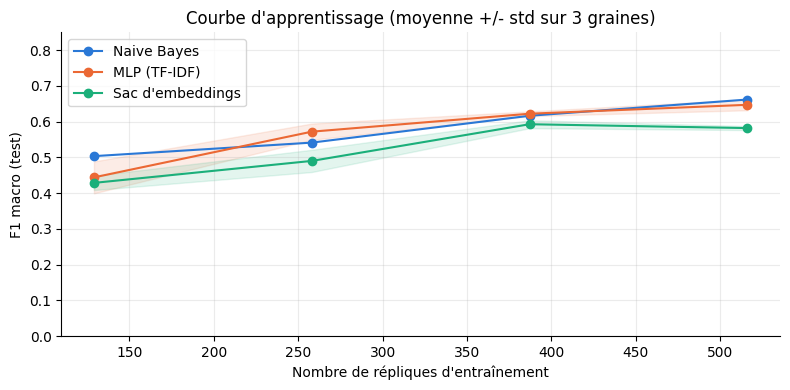

In [20]:
reseau_seq = (
    resume[resume["modèle"] != "MLP (TF-IDF)"]
    .groupby("modèle")["F1 validation"].mean().idxmax()
)
MODELES_COURBE = [meilleur_ml, "MLP (TF-IDF)", reseau_seq]
FRACTIONS = [0.25, 0.5, 0.75, 1.0]
GRAINES_COURBE = GRAINES[:3]

points = []
for frac in FRACTIONS:
    if frac < 1:
        X_sub, _, y_sub, _ = train_test_split(
            X_train, ytr, train_size=frac, stratify=ytr, random_state=RANDOM_STATE
        )
    else:
        X_sub, y_sub = X_train, ytr
    P_sub = preparer(X_sub, y_sub)

    ml = grilles[meilleur_ml][0](modeles_ml[meilleur_ml].get_params()[grilles[meilleur_ml][1]])
    ml.fit(P_sub["vec"].transform(X_sub), y_sub)
    points.append({
        "n": len(X_sub), "modèle": meilleur_ml,
        "F1": f1_score(yte, ml.predict(P_sub["vec"].transform(X_test)), average="macro"),
    })

    for nom in MODELES_COURBE[1:]:
        for g in GRAINES_COURBE:
            m, _, _ = entrainer_dl(nom, P_sub, g)
            pred, _ = predire(m, P_sub[ARCHITECTURES[nom]["entree"]]["test"])
            points.append({"n": len(X_sub), "modèle": nom, "F1": f1_score(yte, pred, average="macro")})

courbe = pd.DataFrame(points).groupby(["modèle", "n"])["F1"].agg(["mean", "std"]).reset_index()
print(courbe.pivot(index="n", columns="modèle", values="mean")[MODELES_COURBE].round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
for couleur, nom in zip(COULEURS, MODELES_COURBE):
    c = courbe[courbe["modèle"] == nom]
    ax.plot(c["n"], c["mean"], color=couleur, marker="o", label=nom)
    if c["std"].notna().any():
        ax.fill_between(c["n"], c["mean"] - c["std"], c["mean"] + c["std"], color=couleur, alpha=0.12)
ax.set_xlabel("Nombre de répliques d'entraînement")
ax.set_ylabel("F1 macro (test)")
ax.set_ylim(0, 0.85)
ax.legend(loc="upper left")
ax.set_title("Courbe d'apprentissage (moyenne +/- std sur 3 graines)")
plt.tight_layout()
plt.show()

## 9. Bilan

Sur 516 exemples, un réseau de neurones entraîné de zéro ne fait pas mieux que Naive Bayes sur TF-IDF :

- Naive Bayes est le meilleur compromis (F1 macro ~0,66, 15 000 paramètres, entraîné en quelques millisecondes).
- Le MLP atteint un score très proche mais avec 50 fois plus de paramètres et un risque de sur-apprentissage rapide.
- Les architectures séquentielles (BiLSTM, BiGRU) et les embeddings appris de zéro souffrent surtout du manque de données et des ~16 % de mots inconnus sur le test.

Pour dépasser ce plafond avec si peu d'exemples étiquetés, il faut partir de représentations déjà apprises sur un grand corpus (modèles pré-entraînés, prompting ou fine-tuning), ce qui fait le lien avec les TP 3 et 4.